In [36]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
from tqdm import tqdm

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik, chi_squared
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
dataset, variances = load_data_and_var()

In [3]:
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances)

In [4]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

In [5]:
test_nfw = nfws[5]

In [6]:
test_nfw.M500.value

354288799999999.94

In [7]:
test_nfw.M500.plus

33280699999999.996

In [8]:
s0 = 1e-27
mx=1e-2

In [55]:
def estimate_uncertainty_monte_carlo(nfw, mx, s0, num_samples=1000):
    # Means and standard deviations for the parameters
    mLinj_mean = 0.38
    mLinj_std = 0.03
    bLinj_mean = 10.0
    bLinj_std = 0.11
    mT500_mean = 4.71
    mT500_std = 0.26
    bT500_mean = -2.34
    bT500_std = 0.09
    
    M500_mean = nfw.M500.value
    M500_std = max(nfw.M500.plus, nfw.M500.minus)

    L500_samples = []
    for _ in tqdm(range(num_samples), desc="Monte Carlo Simulation"):#range(num_samples):
        #mLinj_sample = np.random.normal(mLinj_mean, mLinj_std)
        #bLinj_sample = np.random.normal(bLinj_mean, bLinj_std)
        #mT500_sample = np.random.normal(mT500_mean, mT500_std)
        #bT500_sample = np.random.normal(bT500_mean, bT500_std)
        M500_sample = np.random.normal(M500_mean, M500_std)
        
        scaling_params={
                'mLinj': np.random.normal(mLinj_mean, mLinj_std),
                'bLinj': np.random.normal(bLinj_mean, bLinj_std),
                'mT500': np.random.normal(mT500_mean, mT500_std),
                'bT500': np.random.normal(bT500_mean, bT500_std)
        }
            
        #print(scaling_params)
        #print(M500_sample)

        L500_sample = nfw.precalc.L500_numerical_sampled(M500_sample, mx, s0, scaling_params)
        L500_samples.append(L500_sample)

    L500_samples = np.array(L500_samples)
    uncertainty = np.std(L500_samples)
    return uncertainty

In [34]:
unc_27_2 = estimate_variance_monte_carlo(test_nfw, mx, s0)

Monte Carlo Simulation:   8%|█▎               | 78/1000 [00:08<01:41,  9.06it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.3223634843071447e+44, equation(30): -2.6975175940837214e+53


Monte Carlo Simulation:  38%|██████          | 378/1000 [00:42<01:08,  9.02it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.8817790299187983e+44, equation(30): -1.9831299364144896e+54


Monte Carlo Simulation:  72%|███████████▌    | 722/1000 [01:21<00:31,  8.80it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.207090404895332e+44, equation(30): -1.2953622853281345e+54


Monte Carlo Simulation: 100%|███████████████| 1000/1000 [01:53<00:00,  8.85it/s]


In [35]:
unc_27_2

180.73158663337043

In [16]:
unc_26_2 = estimate_variance_monte_carlo(test_nfw, mx, 1e-26)
unc_26_2

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.5612663090646744e+44, equation(30): -3.083810062774104e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.7700719392414443e+44, equation(30): -7.776012989866864e+53
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.755529790249512e+44, equation(30): -3.246920696242765e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.3501938307547717e+44, equation(30): -2.956251354335723e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.5981879149499296e+44, equation(30): -1.203001268401476e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.132946582715627e+44, equation(30): -1.650784733400483e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.1775521494169796e+44, equation(30): -7.

2.1707215583459395e+22

In [17]:
unc_25_2 = estimate_variance_monte_carlo(test_nfw, mx, 1e-25)
unc_25_2

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.608265927608821e+44, equation(30): -1.3644431573632914e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.029070924623157e+44, equation(30): -1.0178521356551004e+56
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.882150105686281e+44, equation(30): -8.562937456236287e+53
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.2537334267394426e+44, equation(30): -2.3220952606156765e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.156811599120029e+44, equation(30): -6.044310935172432e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.50288005630202e+44, equation(30): -9.818445866236848e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.513172119608053e+44, equation(30): -1.21

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.753164917839091e+44, equation(30): -5.397886772195788e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.280293737572417e+44, equation(30): -7.743866633359993e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.380259330912932e+44, equation(30): -1.536211829658002e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.3580777681181485e+44, equation(30): -7.176554072717459e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.420004011741368e+44, equation(30): -3.48425506998664e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.662788905738341e+44, equation(30): -3.7174377999764895e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.670034115702657e+44, equation(30): -8.9884

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.429857924850465e+44, equation(30): -3.351861766200237e+56
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.725328099196435e+44, equation(30): -6.680548842505601e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.965002237436906e+44, equation(30): -1.6088333591693676e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.2787963133745e+44, equation(30): -5.6612376497359006e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -6.0301469514308024e+44, equation(30): -7.668085433938295e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -6.009436935850181e+44, equation(30): -1.6320777632091676e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.373431023440124e+44, equation(30): -4.658

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.16629324414739e+44, equation(30): -3.395222961733818e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.764479491978581e+44, equation(30): -4.722509497398369e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.488395207477618e+44, equation(30): -1.0155666592649564e+55
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.1390420598201194e+44, equation(30): -3.13832672991293e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -5.4963558731866264e+44, equation(30): -6.21859797537763e+54
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.992850889809061e+44, equation(30): -2.961834116770848e+56
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -4.974967868048322e+44, equation(30): -1.17153

4.527212049934841e+28

In [18]:
unc_24_2 = estimate_variance_monte_carlo(test_nfw, mx, 1e-24)
unc_24_2

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.559404759891213e+46, equation(40): -9.075165254715637e+58
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.2907387807066576e+46, equation(40): -1.9670029726224483e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.0905982616382074e+46, equation(40): -3.142120254827051e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.234721315886803e+46, equation(40): -5.709884751775351e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.5680660112127193e+46, equation(40): -3.216427357625826e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.1129587758914017e+46, equation(40): -1.3533965830751612e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.8003939157906083e+46, equation(40): -

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -1.8059964116791627e+46, equation(40): -8.720127029240296e+58
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.797799199343364e+46, equation(40): -8.864753448491342e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.661470872674757e+46, equation(40): -1.0202228054969513e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.3293877666773366e+46, equation(40): -6.564616763943504e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.265618259921144e+46, equation(40): -4.055849909151873e+57
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.508041254012294e+46, equation(40): -2.5148333344230552e+61
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -1.9440842196062968e+46, equation(40): -6.

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -1.8038040334936816e+46, equation(40): -9.175527896939032e+58
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.2598951860596546e+46, equation(40): -2.2487770615574193e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.6492127732879964e+46, equation(40): -6.267330386039398e+61
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.2596485351103612e+46, equation(40): -4.0046457621979147e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.5967334464840795e+46, equation(40): -2.1774269011458836e+61
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.1980052269938264e+46, equation(40): -1.8445252663193255e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.17599666102976e+46, equation(40):

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.2306138497896463e+46, equation(40): -4.1602376486427805e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.294569449022679e+46, equation(40): -5.56345563974969e+58
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.6698670980343246e+46, equation(40): -1.3329259094684538e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -1.8631349270387592e+46, equation(40): -1.7959322843639012e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.0913603221076875e+46, equation(40): -1.4541268189279004e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.5356837488132095e+46, equation(40): -1.0926588386806464e+61
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -1.911187138219354e+46, equation(40):

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.162755817488071e+46, equation(40): -8.74790167713633e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.3513482891142644e+46, equation(40): -2.6048710710720057e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.366918668861774e+46, equation(40): -5.8610291926070345e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -1.8531088679557906e+46, equation(40): -7.015544873143086e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.3789142766465176e+46, equation(40): -6.66557497948647e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.12048879807415e+46, equation(40): -1.356130910118776e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.166075805917782e+46, equation(40): -4.682

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.1208994693960502e+46, equation(40): -2.7371213973647528e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.3572575014372794e+46, equation(40): -6.726594907826361e+58
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.488999855774782e+46, equation(40): -4.024890392032024e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.4448174164589846e+46, equation(40): -1.6001861770943567e+59
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.1725591989137504e+46, equation(40): -9.525799122689478e+58
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.2290930625770057e+46, equation(40): -2.0741695146213265e+60
Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-1): -2.2640881523056628e+46, equation(40):

4.554931558709935e+38

Text(0, 0.5, 'variance')

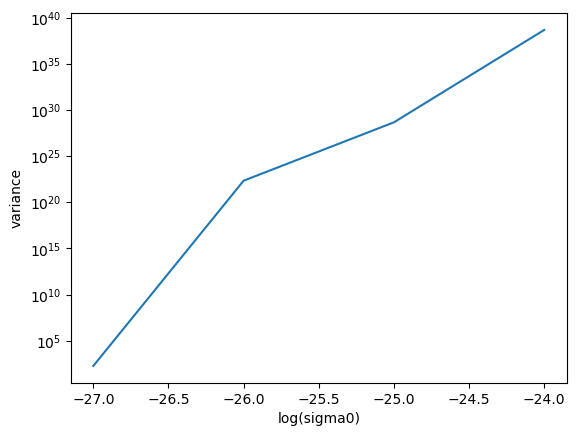

In [24]:
plt.plot([-27, -26, -25, -24], [unc_27_2, unc_26_2, unc_25_2, unc_24_2])
plt.yscale('log')
plt.xlabel('log(sigma0)')
plt.ylabel('variance')

In [25]:
old_unc_27_2 = test_nfw.L500_numerical(1e-2, 1e-27)[1]
old_unc_27_2

370.0639133307998

In [26]:
old_unc_26_2 = test_nfw.L500_numerical(1e-2, 1e-26)[1]
old_unc_26_2

185026508.08418393

In [27]:
old_unc_25_2 = test_nfw.L500_numerical(1e-2, 1e-25)[1]
old_unc_25_2

1.578197657358715e+84

In [28]:
old_unc_24_2 = test_nfw.L500_numerical(1e-2, 1e-24)[1]
old_unc_24_2

3.8856684602391853e+161

Text(0, 0.5, 'variance (old method)')

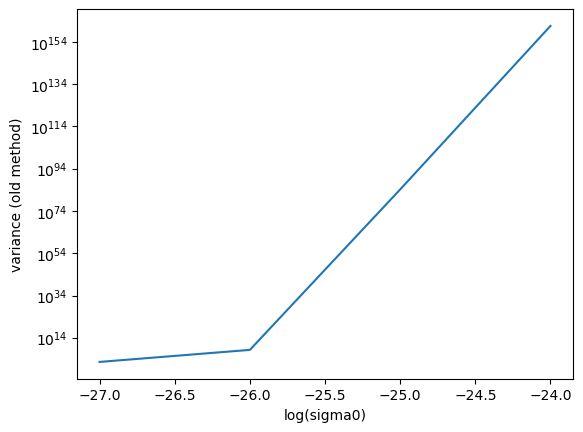

In [29]:
plt.plot([-27, -26, -25, -24], [old_unc_27_2, old_unc_26_2, old_unc_25_2, old_unc_24_2])
plt.yscale('log')
plt.xlabel('log(sigma0)')
plt.ylabel('variance (old method)')

In [40]:
test_nfw.L500.value, test_nfw.L_err

(2.164603, 0.30714760864929636)

In [42]:
test_nfw.L500_numerical(1e-2, 1e-28)

(26.842597492092583, 222.1046719882638)

In [41]:
test_nfw.L500_numerical(1e-2, 1e-27)

(33.507176490104904, 370.0639133307998)

In [45]:
model = test_nfw.L500_numerical(1e-2, 1e-27)[0]
add_var = test_nfw.L500_numerical(1e-2, 1e-27)[1]
X2 = chi_squared(model, test_nfw.L500, test_nfw.L_err, add_var)

In [46]:
log_lik = -X2/2

In [47]:
log_lik

In [48]:
model = test_nfw.L500_numerical(1e-2, 1e-27)[0]
add_var = unc_27_2
X2 = chi_squared(model, test_nfw.L500, test_nfw.L_err, add_var)

In [50]:
log_lik = -X2/2
log_lik

In [53]:
M500_values = [nfw.M500.value for nfw in nfws]
unique_M500_values = set(M500_values)

In [54]:
len(unique_M500_values)

111

In [59]:
nfws_subset = nfws[:10]
s0s = [1e-29, 1e-28, 1e-27, 1e-26, 10**-25.5, 1e-25, 10**-24.75, 10**-24.5, 10**-24.25, 1e-24]

In [64]:
mx=1e-2
def calculate_uncertainties(nfws, s0s, num_samples=1000):
    uncertainties = {}
    for nfw in nfws:
        M500_value = nfw.M500.value
        uncertainties[M500_value] = {}
        for s0 in s0s:
            uncertainty = estimate_uncertainty_monte_carlo(nfw, mx, s0, num_samples=num_samples)
            uncertainties[M500_value][s0] = uncertainty
    return variances

In [65]:
uncertainties = calculate_uncertainties(nfws_subset, s0s)
for M500_value, s0_dict in uncertainties.items():
    for s0, uncertainty in s0_dict.items():
        print(f"Variance for M500={M500_value} and s0={s0}: {uncertainty}")

Monte Carlo Simulation:  85%|█████████████▌  | 849/1000 [01:00<00:11, 13.64it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.6529307430666377e+44, equation(30): -3.1961380151957137e+53


Monte Carlo Simulation:   0%|                  | 4/1000 [00:00<01:08, 14.58it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.7485715863150401e+44, equation(30): -8.641659496198925e+55


Monte Carlo Simulation:   2%|▎                | 18/1000 [00:01<01:06, 14.84it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.9250901758463452e+44, equation(30): -4.332430413693293e+54


... (9 outputs left out)

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.2450445528160782e+44, equation(30): -6.755818667597632e+53


Monte Carlo Simulation:  40%|██████▍         | 400/1000 [00:27<00:40, 14.90it/s]/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:225: RuntimeWarning: overflow encountered in power
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:220: RuntimeWarning: overflow encountered in power
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:185: RuntimeWarning: invalid value encountered in scalar subtract
  return heating_rate - cooling_rate - dm_cooling_rate
/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py:185: RuntimeWarning: invalid value encountered in subtract
  return heating_rate - cooling_rate - dm_cooling_rate
Monte Carlo Simulation:  40%|██████▍         | 400/1000 [00:27<00:40, 14.75it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -1.6210522420526581e+44, equation(30): -2.815267717194626e+53
Error finding log_L_solution with root_scalar: root_scalar did not converge
Unexpected exception formatting exception. Falling back to standard exception



Traceback (most recent call last):
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py", line 199, in L500_numerical_sampled
    log_L_solution = brentq(equation, lower, upper)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py", line 799, in brentq
    r = _zeros._brentq(f, a, b, xtol, rtol, maxiter, args, full_output, disp)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: f(a) and f(b) must have different signs

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_36941/2223770413.py", line 1, in <mod

In [69]:
L500_soln = [test_nfw.L500_numerical(1e-2, s)[0] for s in s0s]

In [74]:
L500_uncs = [estimate_variance_monte_carlo(test_nfw, 1e-2, s) for s in s0s[1:]]

Monte Carlo Simulation:   2%|▎                | 16/1000 [00:01<01:37, 10.11it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -3.0852701140122575e+44, equation(30): -2.0273983174634414e+54
sigma0: 1e-27, mx: 0.01, scaling_params: {'mLinj': 0.3144157049054923, 'bLinj': 9.930302542570963, 'mT500': 4.162397674744447, 'bT500': -2.46257719262048}, M500: 368624520082180.06


Monte Carlo Simulation:  82%|█████████████   | 818/1000 [01:21<00:17, 10.24it/s]

Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.8798693839917046e+44, equation(30): -4.285330413291909e+54
sigma0: 1e-27, mx: 0.01, scaling_params: {'mLinj': 0.34543235302607656, 'bLinj': 10.123048729468625, 'mT500': 3.89391105767113, 'bT500': -2.340951052457674}, M500: 376168736596332.5


Monte Carlo Simulation:  90%|██████████████▍ | 902/1000 [01:29<00:10,  9.62it/s]/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py:315: RuntimeWarning: Derivative was zero.
  warnings.warn(msg, RuntimeWarning)
Monte Carlo Simulation:  90%|██████████████▍ | 903/1000 [01:29<00:09, 10.09it/s]


Error finding log_L_solution: f(a) and f(b) must have different signs
equation(-5): -2.8418047364363732e+44, equation(30): -6.490522932239363e+52
sigma0: 1e-27, mx: 0.01, scaling_params: {'mLinj': 0.3035880895865473, 'bLinj': 10.011824724362915, 'mT500': 4.39194958114727, 'bT500': -2.378080112801035}, M500: 341209174944764.8
Error finding log_L_solution with root_scalar: root_scalar did not converge
Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_precalculations.py", line 199, in L500_numerical_sampled
    log_L_solution = brentq(equation, lower, upper)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py", line 799, in brentq
    r = _zeros._brentq(f, a, b, xtol, rtol, maxiter, args, full_output, disp)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: f(a) and f(b) must have different signs

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3526, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_36941/2814252206.py", line 1, in <modu

Text(0, 0.5, 'L500 numerical solution (1e44 erg/s)')

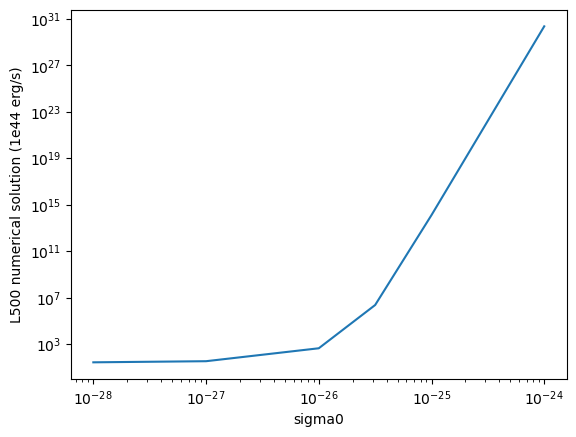

In [72]:
plt.loglog(s0s, L500_soln)
plt.loglog(s0s, L500_uncs)
plt.xlabel('sigma0')
plt.ylabel('L500 numerical solution (1e44 erg/s)')